# Inference Lab: Pricing Under Uncertainty


**Run this notebook in Google Colab.** The `demand` module is compiled for Linux and Python 3.13 only, so it will not import on a Mac or Windows machine.

The goal of this lab is to use what you've learned in this class to find the optimal price for something. You can't know for sure what the underlying curve of revenue vs price looks like. All you know is what you would know in the real world, information you gain by sampling-- you can market test any price using the demand function below. When you set the price, the market test runs for a certain amount of time, and then reports responses-- a list of 1s (bought) and 0s (didn't buy) for that price point. The total number in the sample, $n$, is therefore a random variable, given by `len(responses)`. The number of consumers who buy the product is `responses.sum().` Every time you run a market test, it takes time (literally, it will take a while to run, so don't do this lab last minute!).

In [1]:
!git clone -q https://github.com/smgroves/demand_lab.git

%cd /content/demand_lab

from demand import demand

responses = demand(price=14.0)

print(len(responses), responses.sum())

/content/demand_lab
215 161


## 1. Compare two prices

Run one market test with price = 30. Then test price = 25. Which price earns more revenue per potential customer?

1. For each price, estimate the proportion $\hat{p}$ of customers who buy, and the revenue per customer $\hat{r}$.
2. Estimate the standard error of each $\hat{r}$ by bootstrapping.
3. Compute a 95% confidence interval for each $\hat{r}$.
4. Compute a 95% confidence interval for the difference $\hat{r}_{25} - \hat{r}_{30}$.
   
5. Interpret the estimates, SEs, and intervals. Report which price earns more profit, and how confident you are.



In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng = np.random.default_rng(2026)

price_25, price_30 = 25.0, 30.0
resp_25 = demand(price=price_25)
resp_30 = demand(price=price_30)
B = 2000

boot_idx_25 = rng.integers(0, len(resp_25), size=(B, len(resp_25)))
boot_r_25 = price_25 * resp_25[boot_idx_25].mean(axis=1)

boot_idx_30 = rng.integers(0, len(resp_30), size=(B, len(resp_30)))
boot_r_30 = price_30 * resp_30[boot_idx_30].mean(axis=1)

# estimate and SE
p_hat_25, p_hat_30 = resp_25.mean(), resp_30.mean()
r_hat_25, r_hat_30 = price_25 * p_hat_25, price_30 * p_hat_30
se_25, se_30 = boot_r_25.std(ddof=1), boot_r_30.std(ddof=1)

ci_25 = np.percentile(boot_r_25, [2.5, 97.5])
ci_30 = np.percentile(boot_r_30, [2.5, 97.5])

# bootstrap CI
boot_diff = boot_r_25 - boot_r_30
ci_diff = np.percentile(boot_diff, [2.5, 97.5])
diff_hat = r_hat_25 - r_hat_30

summary = pd.DataFrame([
    {"price": price_25, "n": len(resp_25), "p_hat": p_hat_25, "r_hat": r_hat_25,
     "bootstrap_SE": se_25, "CI_low": ci_25[0], "CI_high": ci_25[1]},
    {"price": price_30, "n": len(resp_30), "p_hat": p_hat_30, "r_hat": r_hat_30,
     "bootstrap_SE": se_30, "CI_low": ci_30[0], "CI_high": ci_30[1]}
])
display(summary.round(3))
print(f"r_25 - r_30 = {diff_hat:.3f}")
print(f"95% bootstrap CI for r_25 - r_30: ({ci_diff[0]:.3f}, {ci_diff[1]:.3f})")
if ci_diff[0] > 0:
    print("The interval is above 0: the data favor price $25.")
elif ci_diff[1] < 0:
    print("The interval is below 0: the data favor price $30.")
else:
    print("The interval contains 0: this sample does not clearly distinguish the two prices.")

,price,n,p_hat,r_hat,bootstrap_SE,CI_low,CI_high
0,25.0,204,0.392,9.804,0.862,8.088,11.4
1,30.0,150,0.407,12.200,1.179,10.000,14.6


r_25 - r_30 = -2.396
95% bootstrap CI for r_25 - r_30: (-5.235, 0.533)
The interval contains 0: this sample does not clearly distinguish the two prices.


Although the price of 30 has the higher estimated revenue, the standard errors of the bootstrap are too large to confidently say that 30 is a definitively better price than 25 since the CI contains zero.

## 2. The cost of sampling

7. Run a second market test at each price. Pool the two price = 30 samples (`np.concatenate`), and pool the two price = 25 samples.
8. Recompute the SEs, the intervals, and the interval for the difference. By roughly what factor did the SE shrink? Explain why, using the SE formula.
   
9.  **Was the extra sampling worth it?** Every market test takes time, and while you're testing you aren't selling at your best price, so each test costs the company revenue. Did the first round already settle the question (its difference interval excluded 0)? If so, the second round cost time and bought nothing but a narrower interval. If not, did the second round settle it?


In [3]:
resp_25_second = demand(price=price_25)
resp_30_second = demand(price=price_30)

pool_25 = np.concatenate([resp_25, resp_25_second])
pool_30 = np.concatenate([resp_30, resp_30_second])

pool_idx_25 = rng.integers(0, len(pool_25), size=(B, len(pool_25)))
pool_boot_r_25 = price_25 * pool_25[pool_idx_25].mean(axis=1)

pool_idx_30 = rng.integers(0, len(pool_30), size=(B, len(pool_30)))
pool_boot_r_30 = price_30 * pool_30[pool_idx_30].mean(axis=1)

pool_r_25, pool_r_30 = price_25 * pool_25.mean(), price_30 * pool_30.mean()
pool_se_25, pool_se_30 = pool_boot_r_25.std(ddof=1), pool_boot_r_30.std(ddof=1)
pool_ci_25 = np.percentile(pool_boot_r_25, [2.5, 97.5])
pool_ci_30 = np.percentile(pool_boot_r_30, [2.5, 97.5])
pool_ci_diff = np.percentile(pool_boot_r_25 - pool_boot_r_30, [2.5, 97.5])

pooled_summary = pd.DataFrame([
    {"price": price_25, "n": len(pool_25), "p_hat": pool_25.mean(), "r_hat": pool_r_25,
     "bootstrap_SE": pool_se_25, "CI_low": pool_ci_25[0], "CI_high": pool_ci_25[1]},
    {"price": price_30, "n": len(pool_30), "p_hat": pool_30.mean(), "r_hat": pool_r_30,
     "bootstrap_SE": pool_se_30, "CI_low": pool_ci_30[0], "CI_high": pool_ci_30[1]}
])
display(pooled_summary.round(3))
print(f"SE ratio (pooled / first test): $25 = {pool_se_25 / se_25:.3f}, "
      f"$30 = {pool_se_30 / se_30:.3f}; expected roughly 1/sqrt(2) = {1/np.sqrt(2):.3f}")
print(f"Pooled r_25 - r_30 = {pool_r_25 - pool_r_30:.3f}")
print(f"95% bootstrap CI for pooled difference: ({pool_ci_diff[0]:.3f}, {pool_ci_diff[1]:.3f})")
if pool_ci_diff[0] > 0:
    print("The pooled interval favors $25.")
elif pool_ci_diff[1] < 0:
    print("The pooled interval favors $30.")
else:
    print("The pooled interval still contains 0, so the comparison remains inconclusive.")


,price,n,p_hat,r_hat,bootstrap_SE,CI_low,CI_high
0,25.0,366,0.415,10.383,0.65,9.085,11.680
1,30.0,297,0.421,12.626,0.85,11.010,14.343


SE ratio (pooled / first test): $25 = 0.754, $30 = 0.721; expected roughly 1/sqrt(2) = 0.707
Pooled r_25 - r_30 = -2.244
95% bootstrap CI for pooled difference: (-4.333, -0.078)
The pooled interval favors $30.


- The standard error shrunk by roughly 1/sqrt(2), which is expected after doubling the sample size since SE shrinks by 1/sqrt(n)
- I believe it was worth running the extra samples since the 95% CI now excludes zero, so we can definitively conclude that 30 is a better price than 25 and will bring in more revenue.

## 3. Finding the optimal price

Now find the price that maximizes revenue per customer. Search prices between about \$5 and \$100.

Every market test takes time, and time spent testing is revenue lost: while you test, you aren't selling at your best price. Your confidence intervals tell you whether another test is worth running. **Use as few market tests as you can (<25 would be good).** Your grade will be based on, in this order, whether you:
- accurately used the information you have by accurately interpreting confidence intervals
- found a good price, close to the optimal price
- and used fewer tests.

If this sounds fun to you, run with it! If you are still very confused about what to do, read the hints below.

<details><Summary>Hints</summary>
<b>Hint 1:</b> There are a few ways you could search:

- Brute force: test every price on a fine grid. This takes a market test at every price, including prices that are obviously bad. This would be a bad choice.
- Hill climbing: compare the CI for two prices, move toward the better one, and repeat. For example, start from the 25/30 comparison above; based on which price is better, choose another price \$10 away in that direction (15 if 25 was better; 40 if 30 was better). Shrink the step size as you get close to a good price. If you can't detect a difference between two prices, either shrink the step size or increase the sample size (i.e. run another market test at the same price).
- other strategies that I won't mention here.
  
<b>Hint 2:</b> You may want to try starting your tests with a few different prices across the range; there may be local maxima you will get stuck in if you just hill climb towards a single maximum.

<b>Hint 3:</b> You can make up your own strategy or try a mix of strategies. However, keep in mind that your grade will reflect how well you ran A/B testing and interpreting confidence intervals, more than how complex your strategy is. Similarly, a lucky guess with a brute force strategy would not be a good reproducible strategy.

<b>Hint 4:</b>
Turn your code from part 1 into a function, so you can easily input responses, run bootstrapping, calculate SE, and calculate confidence intervals. Then make another function where you give it two confidence intervals and make a decision based on them: sample more at the same test, or move in one direction with some step size.
   </details>

**Before you run any tests,** write down your plan: which prices you'll test first, how you'll decide where to go next, and what your intervals need to show before you stop. Then follow it, and note anywhere you changed course and why.

For any method, stop when your intervals show that another test is unlikely to change your answer by enough to matter.

**Deliverable:** A ~2-3 paragraph write up of the strategy you chose, your final recommended price, a 95% CI for $r$ at that price, the number of market tests you ran, and one or two sentences on how your intervals told you when to stop.

,price,n,p_hat,revenue,SE,CI_low,CI_high
0,10.0,185,0.951,9.514,0.158,9.204,9.824
1,20.0,168,0.423,8.452,0.762,6.958,9.946
2,30.0,194,0.381,11.443,1.046,9.393,13.494
3,40.0,217,0.461,18.433,1.354,15.780,21.086
4,50.0,140,0.364,18.214,2.034,14.228,22.200
5,60.0,204,0.235,14.118,1.782,10.625,17.610
6,70.0,222,0.266,18.604,2.075,14.536,22.671


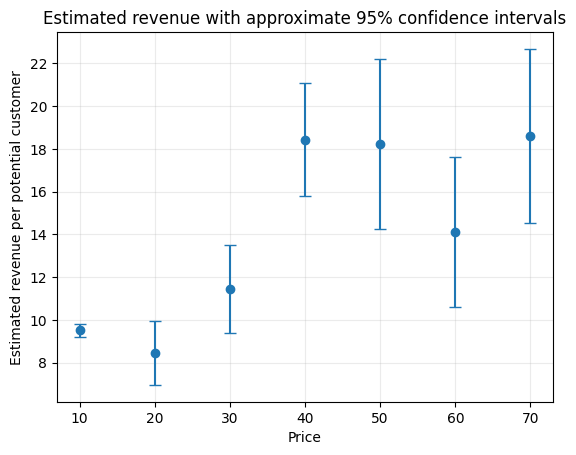

Recommended tested price: $70.00
Estimated revenue: 18.604; approximate 95% CI: (14.536, 22.671)
Market tests in Part 3: 7 (maximum 9)


In [4]:
prices = [10., 20., 30., 40., 50., 60., 70.]
responses = {p: demand(price=p) for p in prices}
best = max(prices, key=lambda p: p * responses[p].mean())

rows = []
for p, y in responses.items():
    n, phat = len(y), y.mean()
    revenue = p * phat
    se = p * np.sqrt(phat * (1 - phat) / n)
    rows.append([p, n, phat, revenue, se, revenue - 1.96 * se, revenue + 1.96 * se])

results = pd.DataFrame(rows, columns=['price', 'n', 'p_hat', 'revenue', 'SE', 'CI_low', 'CI_high']).sort_values('price')
display(results.round(3))

plt.errorbar(results.price, results.revenue, yerr=1.96 * results.SE, fmt='o', capsize=4)
plt.xlabel('Price'); plt.ylabel('Estimated revenue per potential customer')
plt.title('Estimated revenue with approximate 95% confidence intervals')
plt.grid(alpha=0.25); plt.show()

best_row = results.loc[results.revenue.idxmax()]
print(f"Recommended tested price: ${best_row.price:.2f}")
print(f"Estimated revenue: {best_row.revenue:.3f}; approximate 95% CI: ({best_row.CI_low:.3f}, {best_row.CI_high:.3f})")
print(f"Market tests in Part 3: {len(responses)} (maximum 9)")


I used a sequential search to find a price that maximized revenue while trying to limit the amount of market tests. I tested a range of prices (10-70, steps of 10), compared their revenues and CI's, and selected the highest estimated value. This allowed me to narrow the search without testing every possible price.

My final recommended price is 70 dollars, with estimated revenue per customer of 18.604 and an approximate 95% confidence interval of (14.536, 22.671). I conducted 7 market tests staying well below the 25 test threshold. Based on the tested prices, 70 bucks produced the best estimated revenue.

I stopped at seven tests because I feel like the search cast a wide enough net and further testing would have added computational cost without drastically changing the recommended price. However, the confidence interval is still fairly wide, so there's still some uncertainty on if this is the global maximum or not.